# **STEP 3, PART 1.2**

### **The four-parameter grid search, but `alpha_hv=0` and `v_lag` varies.**

Everything is exactly the same but redundant parts are out.

## 0. Settings

In [ ]:
import sys, re, time, json, pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(1, "../EPG_Code/current_version_software")
sys.path.insert(1, "../EPG_Code/mw_addenda")
sys.path.insert(1, "../EPG_Code/fitting")

import grid_search as g
import grid_search_residuals as gr
import pack_grid as pg

# ---------------- where things are ----------------
WORK        = Path("./")                       # local copy of the heron working folder
LAB_PATH    = "../Displays/lab.fit.gz"
PRODUCTS    = "../Convergence/lab_products.npz"
SFR_PROFILE = "../Tests/inputs/sfr_profile_marasco12.txt"
CONV        = Path("../Convergence/conv")      # the convergence-study cubes and their cache (for the noise of each residual)
WORKERS     = 10                               # processes for evaluating the pack on this computer
HERON_WORK  = "<redacted_for_privacy>"

# ---------------- the stage ----------------
STAGE       = "V1"
N_PER_BIN   = 40        # particles per bin of the run (40 = the exploration setting of the convergence study)
N_POINTS    = 512       # Sobol points of this stage (a power of 2 keeps the design balanced!)
SEED0       = 16000     # seeds of this stage: SEED0 ... SEED0 + N_POINTS - 1 (the old grids used < 8000; you can reuse them)
HV0_MAX     = 120.0     # upper edge of hv0 (km/s)

# what one n = 40 run takes and needs: the longest run and the peak memory per worker of the G1 job itself 
# (out_G1_0/job_summary.json: 5.81 min, 788 MB,
# on a full 128-core machine; the single-run probe had said 2.88 min and 687 MB, 
# so the estimate below uses the numbers of the real job)
PROBE_MIN, PROBE_MB, PROBE_N = 5.81, 788.0, 40
FIT_STAGES  = ("V1", )                                 # the stages whose models are fitted (the check stage P1 is not)

# The check stage for Marasco. See Section 6.3.
P1_STAGE, P1_N, P1_SEEDS, P1_SEED0 = "P1", 40, 8, 14000  # seeds 14000 ... 14079 (G1 used 10000 ..., G2 will use 12000 ...)

# ---------------- the comparison with LAB: the same settings as the convergence study ----------------
B_CUT, L_CUT = 0, 0
V_DEV      = 35.0                                          # km/s: |v_dev| below this is disc
REL_FLOOR  = 0.04                                          # K: soft floor of the base relative residual

In [2]:
from mw_io import load_npz, load_lab_products
from mw_display import Cube
from mw_cube import mirror_north_to_full_sky
from mw_mask import (disk_velocity_envelope, mask_disk_emission, mask_named_regions, flat_v_circ, 
                     OUTER_ARM, GCP, EXTERNAL_GAL, MAGELLANIC)
from marasco_comp import *

def build_keep(cube_data, axes, bcut=None):
    l, b, v = axes
    bc = B_CUT if bcut is None else bcut
    vmin, vmax = disk_velocity_envelope(l, b, R0=8.275, v_circ_func=flat_v_circ(220.0))
    excl = mask_disk_emission(cube_data, v, vmin, vmax, v_dev_threshold=V_DEV, return_mask_only=True)
    excl |= mask_named_regions(l, b, v, [OUTER_ARM, GCP] + EXTERNAL_GAL + MAGELLANIC)
    excl |= (np.abs(b) < bc)[None, :, None]
    if L_CUT > 0: excl |= (np.abs((np.asarray(l, float) + 180.0) % 360.0 - 180.0) < L_CUT)[None, None, :]
    return ~excl

def to_full(cube_north, axes):
    full = mirror_north_to_full_sky(Cube(cube_north, *axes, "model"))
    return full.data, (full.l, full.b, full.v)

lab, l_lab, b_lab, v_lab, P = load_lab_products(PRODUCTS, lab_path=LAB_PATH, correction=False)
ax_lab = (l_lab, b_lab, v_lab); keep_lab = build_keep(lab, ax_lab)

# ---------------- the rest of the comparison comes from the loaded LAB product ----------------

SIGMA_NUM  = P.sigma_empty                                 # K: sigma of LAB's noise at 8 deg / 8 km/s
T_M        = 0.04                                          # K: threshold of Marasco's code
K_L        = 2.0                                           # Li-style threshold in sigma
ALPHA_HV   = 0.0                                           # New addition.
RESIDUAL_SETS = {
    "base": dict(kind="soft"),
    "Mrsc": dict(kind="select", T=T_M, rel="max", blanks=False),
    "Li":   dict(kind="select", k=K_L, sigma=SIGMA_NUM, rel="max", blanks=True),
}
TAG = f"v{V_DEV:g}_L{L_CUT:g}_B{B_CUT:g}_f{REL_FLOOR:g}_T{T_M:g}_k{K_L:g}_s{SIGMA_NUM*1e3:.2f}"
# every setting that changes a residual (names the caches).

if ALPHA_HV == 0.0: TAG += "_ahv0"

RES_DIR = WORK / "results"
RES_DIR.mkdir(parents=True, exist_ok=True)

RUNS_DIR = WORK / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)
RUN_FILE = RUNS_DIR / f"grid4d_{STAGE}.json"
print(f"Stage {STAGE}: run file in {RUN_FILE}; residual settings tag {TAG} on cache.")

> Seam columns differ by at most 4.5024986 K
LAB products of 2026-10-22: sigma = 3.123 mK (empty channels), 3.236 mK (null test)
Correction file on same directory: none
Note: correction=False, the stored correction is NOT applied; the stored sigma belongs to the corrected cube.
Stage V1: run file in runs/grid4d_V1.json; residual settings tag v35_L0_B0_f0.04_T0.04_k2_s3.12_ahv0 on cache.


## 1. The design: which parameters does a run use?

Four parameters are varied, in the box of the earlier search:

| parameter | box | meaning |
|---|---|---|
| `hv0` | 50 ... `HV0_MAX` km/s | ejection velocity scale |
| `alpha_conds` | 0 ... 10 Gyr$^{-1}$ | condensation rate (0 = none) |
| `alpha_hv` | 0 ... 0.5 (open) | radial dependence of the ejection velocity |
| `f_ion` | 0 ... 1 | 0 = neutral over the whole orbit, 1 = neutral only while falling |

**Everything else is fixed, and is written into every run.** 

The fixed values are read from `multi_run.py` itself (its `SAMPLING_KW` and `P_REF`, the values of the convergence study), so the run file and the model cannot disagree about them. After this cell, `multi_run.py` has nothing left to fill in.

In [3]:
HAVE_SFR = Path(SFR_PROFILE).exists()
sfr = np.loadtxt(SFR_PROFILE) if HAVE_SFR else None
sfrd = (lambda R: np.interp(np.asarray(R, float), sfr[:, 0], sfr[:, 1])) if HAVE_SFR else None
box  = g.Box(names=("hv0","alpha_conds","vlag","f_ion"), lo=(50.0, 0.0, 20.0, 0.0), hi=(HV0_MAX, 10.0, 150.0, 1.0))
feat = g.Features(box, sfrd=sfrd, alpha_hv=ALPHA_HV)
print("box:", {n: (lo, hi) for n, lo, hi in zip(box.names, box.lo, box.hi)})
print("SFRD profile found: hv(R_pivot) uses the true SFRD ratio" if HAVE_SFR \
      else "SFRD profile NOT found: hv(R_pivot) is computed with ratio 1 (edit SFR_PROFILE)")

FIXED = gr.fixed_from_run_conv(varied=box.names)
FIXED["alpha_hv"] = ALPHA_HV # By default it is 0.2, not 0.
# read from multi_run.py: SAMPLING_KW + P_REF without the four varied parameters
theta = box.from_unit(g.sobol_unit(N_POINTS, box.ndim, seed=31))
runs  = gr.design_runs(theta, STAGE, N_PER_BIN, SEED0, box.names, FIXED)

clash = gr.seeds_used_elsewhere(RUNS_DIR, STAGE) & {r["seed"] for r in runs.values()}
assert not clash, f"Seeds already used by another stage: {sorted(clash)[:5]}"

print()
gr.print_design(runs, varied=box.names)

box: {'hv0': (50.0, 120.0), 'alpha_conds': (0.0, 10.0), 'vlag': (20.0, 150.0), 'f_ion': (0.0, 1.0)}
SFRD profile found: hv(R_pivot) uses the true SFRD ratio

512 runs; every run lists these 12 parameters:
  n_per_bin    fixed       40.0000
  alpha_conds  varied       0.0105 ...     9.9882
  f_ion        varied       0.0013 ...     0.9996
  hv0          varied      50.0237 ...   119.9690
  vlag         varied      20.1484 ...   149.9056
  R_clump      fixed        0.1000
  R_disk       fixed       30.0000
  alpha_hv     fixed        0.0000
  dR           fixed        0.2500
  max_R        fixed       20.0000
  min_R        fixed        0.5000
  n_iter_add   fixed      900.0000
  seeds 16000 ... 16511 (one per run, az_seed = 100 x seed)


**The first run, in full** — this is exactly what `create_cube_MW` receives for run `G1_0000` (plus its two seeds). Under it, the same dictionary after `multi_run.py` has merged in its own defaults: **if the two are identical, nothing is filled in behind your back.**

In [4]:
import multi_run, inspect

first = next(iter(runs))
kw = runs[first]["kw"]
print(first, json.dumps(kw, indent=1), "seed", runs[first]["seed"], "azimuth_seed", runs[first]["az_seed"])

merged = {**multi_run.SAMPLING_KW, **multi_run.P_REF, **kw}                  # what multi_run.run_one does
assert merged == kw, f"multi_run.py would fill in: { {k: v for k, v in merged.items() if k not in kw} }"

V1_0000 {
 "n_per_bin": 40,
 "hv0": 53.17561005242169,
 "alpha_conds": 9.520719097927213,
 "vlag": 87.11840811185539,
 "f_ion": 0.965648990124464,
 "dR": 0.25,
 "min_R": 0.5,
 "max_R": 20.0,
 "R_disk": 30.0,
 "alpha_hv": 0.0,
 "n_iter_add": 900,
 "R_clump": 0.1
} seed 16000 azimuth_seed 1600000


The model also has constants that no run file changes (the Sun's position, the grid of the output cube, the input files). They sit in `setup_model()` of `multi_run.py` and in `input_MW.yaml` on `heron`; they are the same for every run. Printed here so that they are in front of us if we need to inspect them:

In [5]:
print(inspect.getsource(multi_run.setup_model))

def setup_model():
    """
    Initialize global Milky Way model parameters (`mw_init.param`) and return the 
    cube generation callable (`mw_cube.create_cube_MW`).
    """

    param.init_params_MW(
        path_yaml="input_MW.yaml",
        path_sfr_profile="sfr_profile_marasco12.txt",
        l_min=0.0,
        l_max=360.0,
        dl=1.0,
        b_min=0.0,
        b_max=90.0,
        db=1.0,
        v_min=-400.0,
        v_max=400.0,
        dv=4.0,
        R0_kpc=8.275,
        z_sun_kpc=0.0,
        v_sun_kms=(0.0, None, 0.0),
        path_to_files=INPUTS,
        shift_l0_to_center=True,
        hush_print=True,
    )
    return create_cube_MW



Now the run file is written. **A run file is never overwritten**: the cubes of a stage belong to the parameters in its file, so a changed design needs a new `STAGE`. If the file already exists the cell checks that it is identical (re-running the notebook is safe) and uses the file on disk as the truth.

Run file: identical
512 runs in grid4d_V1.json; n_per_bin = [40]


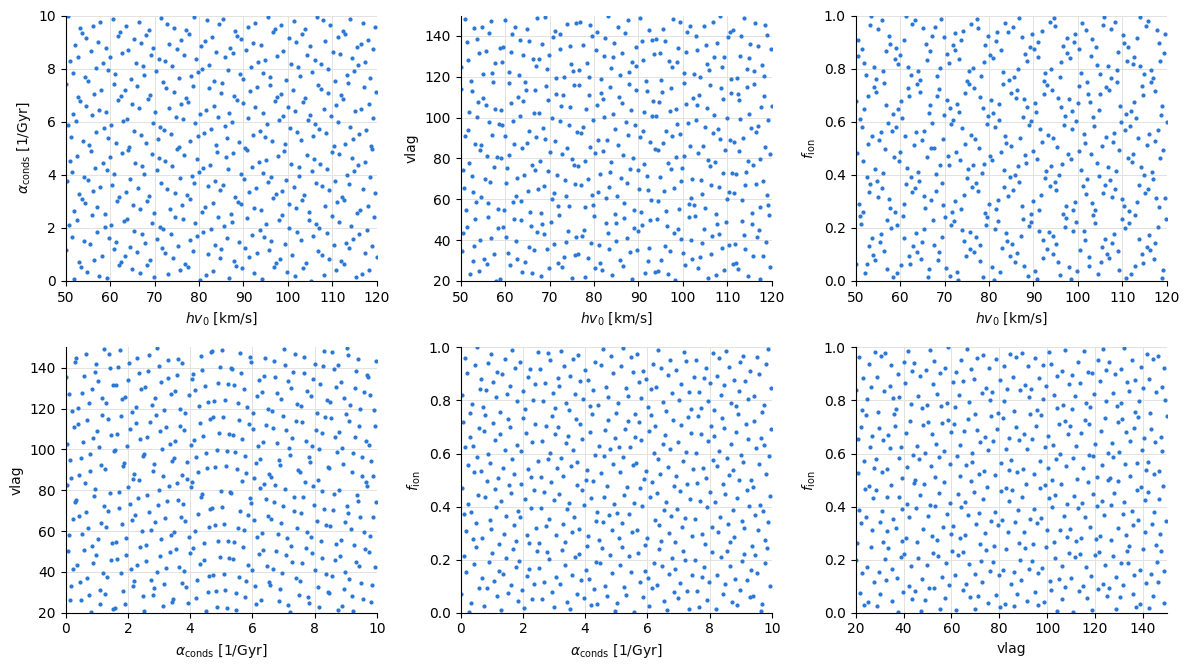

In [6]:
try:
    print("Run file:", g.save_runs(runs, RUN_FILE))
except FileExistsError as e:
    print("NOT written:", e)
    print("-> The run file on disk is used from here on; change STAGE (or N_POINTS back) if you wanted a different design.")

runs = g.load_runs(RUN_FILE)
theta = np.array([[runs[k]["kw"][n] for n in box.names] for k in runs])
print(f"{len(runs)} runs in {RUN_FILE.name}; n_per_bin = {sorted({r['kw']['n_per_bin'] for r in runs.values()})}")

gr.plot_design(theta, box)
plt.show()

**How long will it take, and how much memory?** 

From the numbers of the `G1` job itself (the longest $n = 40$ run took 5.8 min on the full machine and the largest worker held 788 MB; the single-run probe before it had said 2.9 min and 0.7 GB, so a full machine is slower than a probe), assuming that time and memory grow in proportion to `n_per_bin` (check this with a probe at $n = 160$ before running a large $n = 160$ stage), `NWORK = 128` workers and longest runs first.

In [7]:
est = gr.job_estimate(runs, PROBE_MIN, PROBE_MB, workers=128, n_probe=PROBE_N, slow=1.0)
need = gr.memory_advice(est, current_gb=256)
print(f"\nAfter the job, out_{STAGE}_0/job_summary.json lists the longest run and the peak memory that were really used: "
      "\nput them into PROBE_MIN, PROBE_MB (settings) for the next estimate.")

512 runs on 128 workers: about 23 min wall (longest run 5.8 min, +0% for a busy machine); memory 98 GB -> request_memory = 129G
memory: models 98 GB at once, packing 56 GB (16 processes of ~3.5 GB) -> request_memory >= 129G; <submit_file>.sub has 256G: enough.

After the job, out_V1_0/job_summary.json lists the longest run and the peak memory that were really used: 
put them into PROBE_MIN, PROBE_MB (settings) for the next estimate.


## 2. Run it on `heron`

Copy the run file next to `run_conv.py` on `heron`, set the stage in `<submit_file>.sub`, submit:

```bash
scp runs/grid4d_G1.json  <redacted_for_privacy>/runs/
# in <submit_file>.sub:   STAGE = G1      (RUNS, the output folder and the log names follow from it)
cd <redacted_for_privacy>;  mkdir -p logs
condor_submit <submit_file>.sub
condor_q --better-analyze
condor_tail -f <jobid>
```

The job starts the 128 workers, **packs the finished cubes itself** (the `--pack` in the `arguments` line of `<submit_file>.sub`), and returns the folder `out_G1_0/`. In it:

* `pack.fits` — the whole grid in one file (about 0.5 MB per model);
* `params_effective.csv` — the parameters each run really used (the job's own record);
* `job_summary.json` — wall time, longest run, peak memory;
* `G1_0000.npz` ... — the native cubes (large; leave them on `heron`, or delete them once you trust the pack);
* `timings/`, `log_worker*.txt` — per-run times and worker logs.

We do **not** call the packing yourself. `pack_grid.py` is only for: joining the packs of several shards, adding later runs to a pack, packing with other settings (another `V_DEV`, `B_CUT`...), and `verify`. If the job log says `packing skipped: radio_beam is missing`, the models are fine and the log tells us the one-line fix to do the packaging ourselves later.

In [ ]:
def copy_cmds(stage):
    print(f'''Copy commands for stage {stage}:

  scp {RUNS_DIR / f"grid4d_{stage}.json"}  {HERON_WORK}/runs/                                   # before the job
  mkdir -p {WORK}/out_{stage}_0
  scp "{HERON_WORK}/out_{stage}_0/pack.fits"  "{HERON_WORK}/out_{stage}_0/params_effective.csv"  "{HERON_WORK}/out_{stage}_0/job_summary.json"  {WORK}/out_{stage}_0/     # after the job
''')

copy_cmds(STAGE)

## 3. Bring the packaged grids

This step reads the pack(s) of all stages found in `WORK/out_*_*/pack.fits` (several shards or stages, the check stage `P1` included, are joined into `WORK/grid_all.fits`). **If nothing has been copied yet, the cell stops here: do steps 1-2 first.**

Three checks, all on the parameters:
1. the pack was made with the same masks and comparison grid as this notebook (`pack.check`);
2. every model in the pack is a run of a run file, with **the same parameters and seeds** (`compare_pack_to_runfile`);
3. the job's own log of what it used (`params_effective.csv`) says that nothing was filled in.

In [9]:
PACK_FILES = sorted(WORK.glob(f"out_{STAGE}_*/pack.fits"))

if not PACK_FILES:
    raise RuntimeError(f"No pack.fits found in {WORK}/out_*_*/ : "
                       "run the job (step 2) and copy pack.fits home first (the copy commands are printed above)")

pack = gr.open_packs(PACK_FILES, RES_DIR / "grid_all_ahv0.fits")

print(f"{len(PACK_FILES)} pack file(s): {[str(f.parent.name) for f in PACK_FILES]}")
print(f"{len(pack)} models; written on {pack.header.get('HOST')} at "
      f"{pack.header.get('CREATED')}; compression: {'lossless' if pack.bits == 0 else str(pack.bits) + ' bits'}")

RUNS_ALL = {}
for f in sorted(RUNS_DIR.glob("grid4d_*.json")):
    RUNS_ALL.update(g.load_runs(f))

print()
for f in PACK_FILES:                                                        # each job's own record against its run file
    csv = f.parent / "params_effective.csv"
    print(f"--- {f.parent.name} ---")
    with pg.GridPack(f) as p1:
        chk = gr.compare_pack_to_runfile(p1, RUNS_ALL, csv=csv if csv.exists() else None)
    if not csv.exists(): print("  (params_effective.csv not copied: only the pack against the run file was checked)")
    summ = f.parent / "job_summary.json"
    if summ.exists():
        s = json.load(open(summ))
        print(f"  job: {s['runs_done']}/{s['runs_in_share']} runs on {s['host']} with {s['workers']} workers, "
              f"wall {s['wall_minutes']} min, longest run {s['longest_run_minutes']} min,\n"
              f"       peak {s['peak_worker_mb']} MB per worker (request_memory hint {s['request_memory_hint_gb']} GB)\n")
        
    assert chk["ok"], "The models of the pack are not the runs of the run file: do not continue."

1 pack file(s): ['out_V1_0']
512 models; written on heron8 at 2026-10-17T09:15:30; compression: lossless

--- out_V1_0 ---
pack: 512 models; run file(s): 1616 runs; in both: 512.
  params_effective.csv (512 rows, written by the job on heron): same as the run file, nothing filled in..
  -> every model was run with exactly the parameters its run file lists; nothing was filled in.
  job: 512/512 runs on heron8 with 128 workers, wall 19.58 min, longest run 9.61 min,
       peak 787 MB per worker (request_memory hint 128 GB)



## 4. Evaluate: all residuals on all models

The LAB side is built exactly as in the convergence study: the same masks, the same comparison grid, the same residual sets. Then **every model of the pack is evaluated once, with every residual key** (`abs`, `sq`, `rel` in the base, `Mrsc` and `Li` sets); the evaluation is cached (the file name carries every setting that changes a residual), so adding a later stage only evaluates the new models.

In [10]:
cmp = MarascoComparison(lab, ax_lab, keep_lab, build_keep, to_full, 
                        CompareConfig(beam_fwhm=8.0, sampling=4.0, dv=8.0), 
                        rel_floor=REL_FLOOR, residual_sets=RESIDUAL_SETS)
cfg = cmp.cfg
KEYS, SETS = list(cmp.keys), list(cmp.sets)
pack.check(cfg=cfg, V_DEV=V_DEV, B_CUT=B_CUT, L_CUT=L_CUT) # raises if the pack was made with other masks / comparison settings

print(f"Comparison grid {len(cmp.v)} channels x {len(cmp.b)} b x {len(cmp.l)} l; pack settings match this notebook.")
print("Residual keys:", KEYS)

Comparison grid 62 channels x 41 b x 90 l; pack settings match this notebook.
Residual keys: ['abs', 'sq', 'rel', 'abs_Mrsc', 'sq_Mrsc', 'rel_Mrsc', 'abs_Li', 'sq_Li', 'rel_Li']


In [11]:
CACHE = RES_DIR / f"grid_resid_{TAG}.pkl"
RES = gr.evaluate_pack(pack, cmp, cache=CACHE, workers=WORKERS)               # every model of the pack, whatever its stage
RUNS_FIT = {k: r for k, r in pack.runs().items() if r["group"] in FIT_STAGES} # the models of the fit
RES_FIT = {k: RES[k] for k in RUNS_FIT}
tab = gr.residual_table(RES_FIT, pack)

print(f"{len(RES)} models evaluated (cache {CACHE.name});\n"
      f"{len(RUNS_FIT)} of them in the fit (stages {FIT_STAGES});\n"
      f"Stages in the pack: {sorted({r['group'] for r in pack.runs().values()})}")

for s in SETS:
    if f"n_sel_{s}" in tab: 
        print(f"> set {s:5s}: {np.mean(tab['n_sel_' + s]):8.0f} voxels selected on avg (of {RES[tab['name'][0]]['n_valid']})")

512 new evaluations in 57 s; 512 models evaluated
512 models evaluated (cache grid_resid_v35_L0_B0_f0.04_T0.04_k2_s3.12_ahv0.pkl);
512 of them in the fit (stages ('V1',));
Stages in the pack: ['V1']
> set Mrsc :    29615 voxels selected on avg (of 160304)
> set Li   :    99609 voxels selected on avg (of 160304)


**First look at how the residuals relate (models of the fit only).**

The best model of each residual (smallest $R$), and how similarly the residuals rank the models. A Spearman rank correlation near 1 means that two residuals are different ways to say the same thing for this grid; a low one means they will put the optimum in different places.

residual   best model              R          hv0  alpha_conds         vlag        f_ion   (smallest R)
abs        V1_0259              3001       74.027        4.337      145.851        0.192
sq         V1_0424             863.8       67.412        8.081       65.019        0.230
rel        V1_0212          1.96e+04       76.527        8.510      123.353        0.109
abs_Mrsc   V1_0415              2318       50.942        4.534       90.889        0.243
sq_Mrsc    V1_0424             854.3       67.412        8.081       65.019        0.230
rel_Mrsc   V1_0471              9505       66.749        2.710      113.678        0.867
abs_Li     V1_0259              2895       74.027        4.337      145.851        0.192
sq_Li      V1_0424             863.2       67.412        8.081       65.019        0.230
rel_Li     V1_0265         4.957e+04       90.731        4.946       47.324        0.006


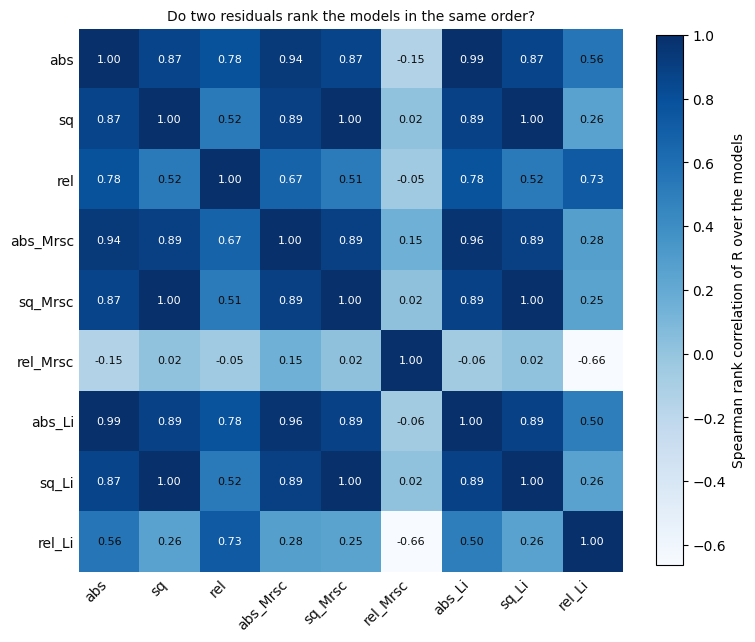

In [12]:
print(f"{'residual':10s} {'best model':12s} {'R':>12s} " + " ".join(f"{n:>12s}" for n in box.names) + "   (smallest R)")
for k in KEYS:
    i = int(np.argmin(tab["R_" + k]))
    print(f"{k:10s} {tab['name'][i]:12s} {tab['R_' + k][i]:12.4g} " + " ".join(f"{tab[n][i]:12.3f}" for n in box.names))
C = gr.rank_correlation(tab, KEYS)
gr.plot_rank_correlation(C, KEYS); plt.show()

## 5. Fit: one surface and one optimum per residual

**The noise of each residual** comes from the convergence study: the relative scatter of $R$ between seeds at $n = 40$ (and at the other $n$, for later stages). If the cache of the convergence study is found it is used (same `TAG`); otherwise the numbers measured there are used (`NOISE_FALLBACK` in `grid_search_residuals.py` as approximates).

In [13]:
PK_CONV = CONV / f"marasco_conv_{TAG}.pkl" # same tagline. If something new is needed, go back and run convergence.
RES_CONV = pickle.load(open(PK_CONV, "rb")) if PK_CONV.exists() else {}
RES_CONV = {n: r for n, r in RES_CONV.items() if r.get("keys") == KEYS}

GN = {}
for nm in RES_CONV:
    m = re.match(r"N(\d+)_s(\d+)$", nm)
    if m: GN.setdefault(f"N{m[1]}", []).append(nm)

if RES_CONV and len(GN.get("N40", [])) >= 3:
    NOISE = gr.noise_table_from_conv(RES_CONV, GN, KEYS)
    print(f"Noise table from the convergence cache {PK_CONV.name} "
          f"({ {k: len(v) for k, v in sorted(GN.items())} } seeds per n)")
else:
    NOISE = {k: dict(gr.NOISE_FALLBACK[k]) for k in KEYS}
    print("Convergence cache not found: using the noise table measured in the convergence study (gr.NOISE_FALLBACK)")

print(f"{'residual':10s} " + " ".join(f"{'n=' + str(n):>8s}" for n in (10, 20, 40, 80, 160)) + 
      "   (relative std over seeds, %)")

for k in KEYS:
    print(f"{k:10s} " + 
          " ".join(f"{100 * NOISE[k][n]:8.2f}" if n in NOISE[k] else f"{'-':>8s}" for n in (10, 20, 40, 80, 160)))

Convergence cache not found: using the noise table measured in the convergence study (gr.NOISE_FALLBACK)
residual       n=10     n=20     n=40     n=80    n=160   (relative std over seeds, %)
abs            2.84     1.54     1.29     0.61     0.30
sq            10.69     4.50     4.47     2.38     1.29
rel            1.15     2.40     1.02     0.56     0.30
abs_Mrsc       3.36     1.44     1.38     0.69     0.32
sq_Mrsc       10.79     4.51     4.50     2.40     1.30
rel_Mrsc       2.16     2.64     1.32     1.28     0.80
abs_Li         2.91     1.55     1.34     0.64     0.30
sq_Li         10.70     4.51     4.48     2.38     1.29
rel_Li         1.31     3.17     1.04     0.56     0.39


**Finite-$n$ bias.** 

Residuals computed with few particles are slightly biased ($R(n) = R_\infty + b/n$). While every run of the fit has the same $n$ (stage `G1` alone) this is a constant offset that does not move the optimum, so we use `USE_BIAS = False`. When a stage with another $n$ (e.g. 160) joins the fit, this now needs to be `True`. $b$ is then fitted per residual from the convergence groups and removed before the logarithm.

In [14]:
USE_BIAS = False
BIAS = {k: gr.fit_bias(RES_CONV, GN, k) for k in KEYS} if (USE_BIAS and RES_CONV) else None
n_levels = sorted({int(r["kw"]["n_per_bin"]) for r in RUNS_FIT.values()})

print("n_per_bin in the fit:", n_levels, "| bias correction:", "on" if BIAS else "off")
if len(n_levels) > 1 and not BIAS:
    print("WARNING: several n_per_bin in the fit and no bias correction: set USE_BIAS = True (needs the convergence cache)")

n_per_bin in the fit: [40] | bias correction: off


**The fit.** 

For every residual key: the Gaussian-process surface (quadratic mean + Matérn-5/2, noise per run from the table above), the posterior of the optimum from joint draws of the surface, and the data-side uncertainty from the leave-one-longitude-sector-out jackknife. This takes about a minute per residual for 512 models (about seven minutes for the 9 residuals).

Then, **the result is stored** (`grid_fit_<TAG>.pkl`) and read back when the models, the residuals and the settings are the same, so re-running the notebook from the top does not repeat it.

In [15]:
OUT = gr.optima_cached(RES_DIR / f"grid_fit_{TAG}.pkl", RES_FIT, RUNS_FIT, KEYS, NOISE, 
                       box, feat, n_draws=200, n_restarts=6, bias=BIAS)
print()
gr.print_optima(OUT)

fitted 9 residuals in 400 s; stored in grid_fit_v35_L0_B0_f0.04_T0.04_k2_s3.12_ahv0.pkl

residual      n                        hv0                alpha_conds                       vlag                      f_ion                hv(R_pivot)
                 median +- GP +- jackknife  median +- GP +- jackknife  median +- GP +- jackknife  median +- GP +- jackknife  median +- GP +- jackknife
abs         512   78.189 +- 7.386 +-34.252    5.521 +- 1.458 +- 2.904  118.873 +-29.326 +-55.028    0.000 +- 0.014 +- 0.107   78.189 +- 7.386 +-34.252
sq          512   63.719 +- 2.750 +- 9.191    5.248 +- 0.614 +- 0.543  104.512 +-15.404 +-44.269    0.000 +- 0.008 +- 0.016   63.719 +- 2.750 +- 9.191
rel         512   58.940 +-10.145 +-21.258    9.999 +- 0.247 +- 1.212  149.987 +- 0.333 +-47.260    0.609 +- 0.324 +- 0.920   58.940 +-10.145 +-21.258
abs_Mrsc    512   59.631 +- 5.169 +-30.826    5.579 +- 1.343 +- 3.001  103.903 +-19.247 +-48.007    0.152 +- 0.094 +- 0.315   59.631 +- 5.169 +-30.826
sq_Mr

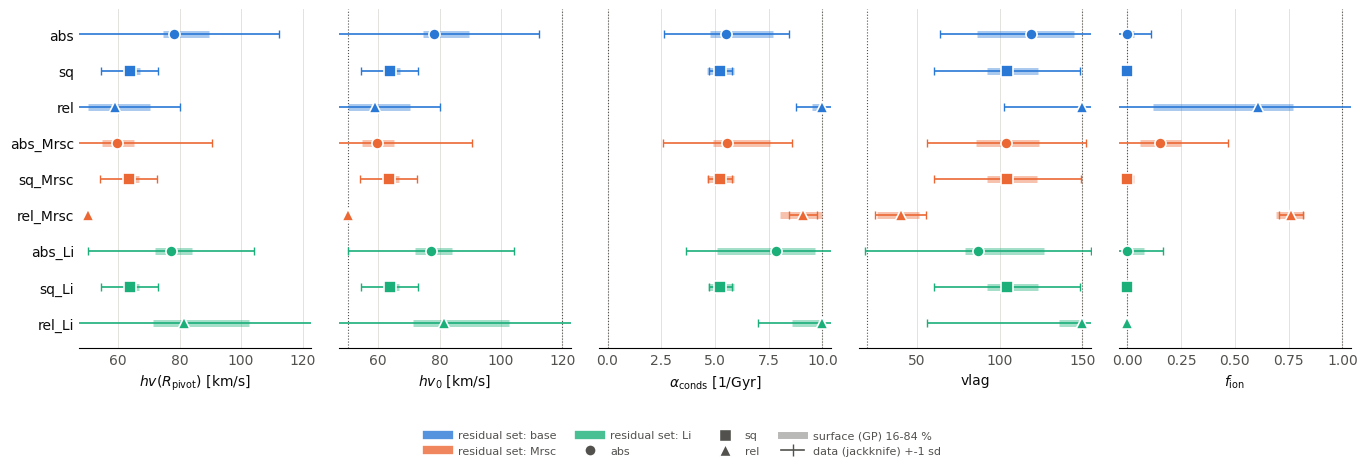

In [16]:
fig = gr.plot_optima(OUT, box, feat=feat)
plt.show()

**Reading the plot.** 

One row per residual, one panel per parameter. 
- The dot is the posterior median of the optimum.
- The thick bar the 16-84 % range from the surface (how well the 512 models pin down the maximum of the fitted surface).
- The whisker the jackknife $\pm 1\sigma$ (how much LAB itself, sector by sector, moves the optimum). 
- Color is the residual set (blue base, orange `Mrsc`, green `Li`).
- Marker is the observable (circle `abs`, square `sq`, triangle `rel`).
- Dotted lines are the edges of the box and the axes end there (a whisker that runs out of the box is cut): an optimum on an edge is a limit, not a value.

**How well-behaved is each surface?** 

Fitted noise scale ($1$ = the noise assumed from the convergence study; much larger means the surface has structure the runs do not explain), leave-one-out $z$ (should have mean $0$, standard deviation $1$), length scales ($4$ = at the bound = flat in that direction) and the share of the optimum's posterior sitting on a box edge. The leave-one-out loop adds about 15 seconds per residual.

In [17]:
ST = gr.surface_table(OUT, box)

residual    runs  noise x  extra         LOO z   length scales (   hv0 alpha_conds   vlag  f_ion)   share at box edge
abs          512     0.97   0.72  -0.00  1.00      (  1.98   0.50   0.57   1.13)   f_ion:lo 88%
sq           512     1.06   0.06  +0.00  1.00      (  2.69   0.97   1.25   4.00)   f_ion:lo 85%
rel          512     1.04   0.29  -0.00  1.00      (  1.70   1.42   1.53   1.92)   hv0:lo 27%, alpha_conds:hi 78%, vlag:hi 95%
abs_Mrsc     512     0.96   0.92  -0.00  1.00      (  2.52   0.70   0.78   1.77)   -
sq_Mrsc      512     0.82   0.68  +0.00  1.00      (  2.68   0.97   1.25   4.00)   f_ion:lo 85%
rel_Mrsc     512     1.37   0.85  -0.00  1.00      (  3.41   2.01   2.19   3.48)   hv0:lo 100%, alpha_conds:hi 38%
abs_Li       512     1.15   0.23  -0.00  1.00      (  1.60   0.40   0.47   0.99)   f_ion:lo 72%
sq_Li        512     1.06   0.10  +0.00  1.00      (  2.69   0.97   1.25   4.00)   f_ion:lo 85%
rel_Li       512     1.00   0.22  -0.00  1.00      (  1.21   0.91   1.09   

**One residual in detail.** 

From the residuals we inspect, then we choose the key to get, more in depth. the profiles of its surface along each parameter (grey dots: the evaluated models), the two-parameter slices through its optimum, and the one-sided limits for parameters that sit on an edge.

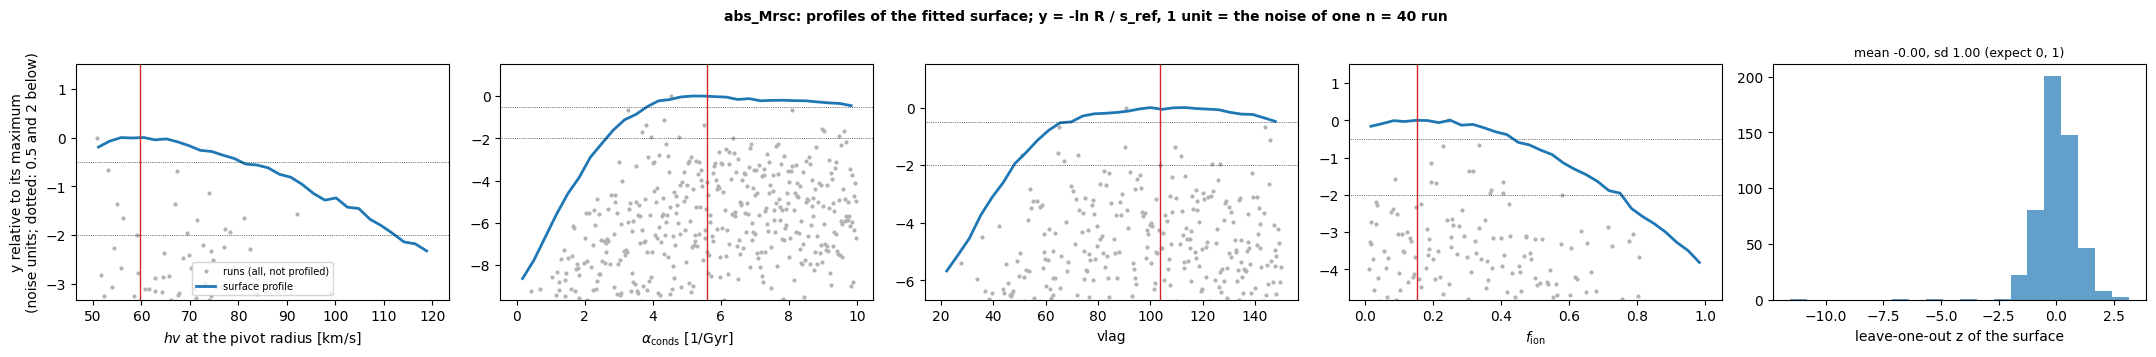

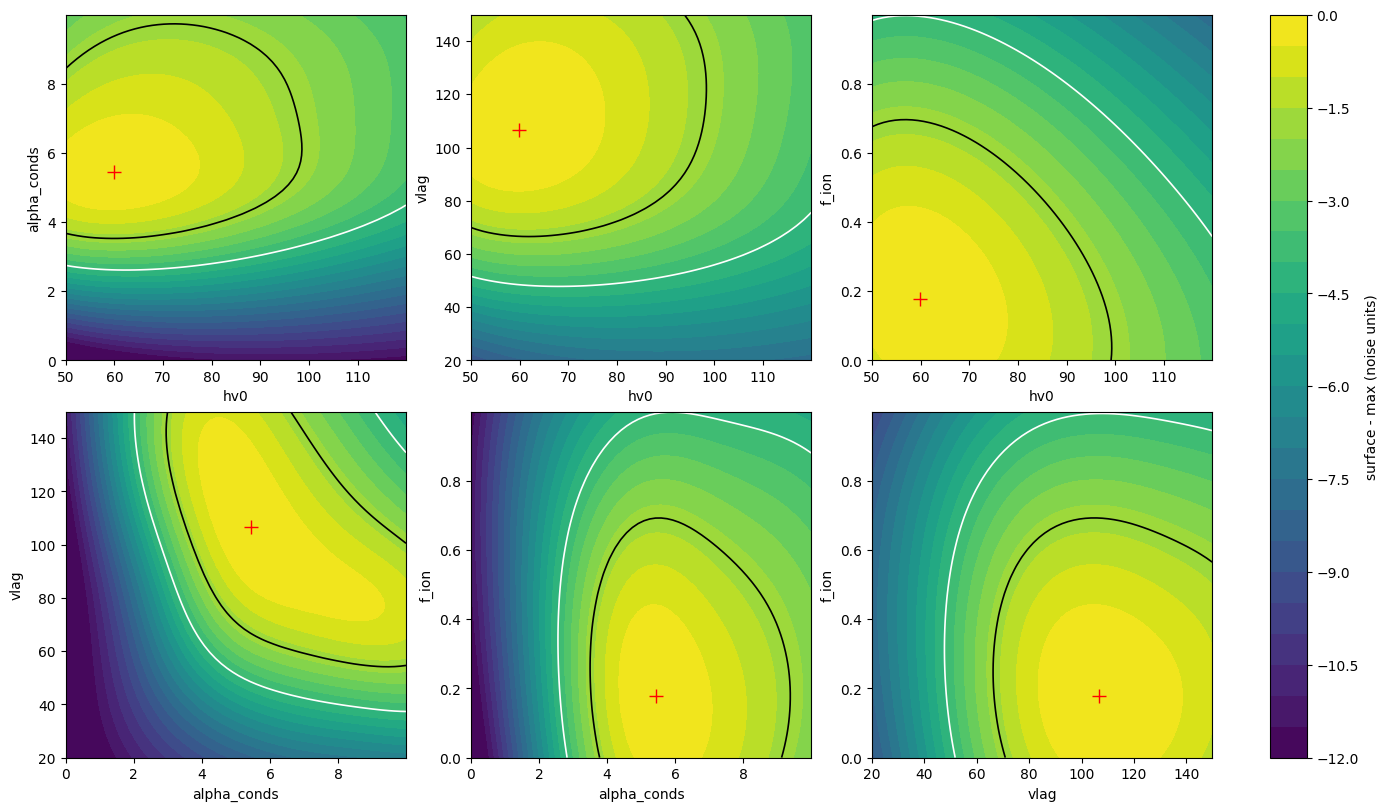

  profile hv_pivot     {0.5: (50.44, 81.061, 'lo-edge'), 2.0: (50.44, 110.807, 'lo-edge')}
  profile hv0          {0.5: (50.44, 81.061, 'lo-edge'), 2.0: (50.44, 110.807, 'lo-edge')}
  profile alpha_conds  {0.5: (4.062, 9.812), 2.0: (2.812, 9.937, 'hi-edge')}
  profile vlag         {0.5: (71.183, 147.55), 2.0: (50.06, 149.175, 'hi-edge')}
  profile f_ion        {0.5: (0.006, 0.431, 'lo-edge'), 2.0: (0.006, 0.731, 'lo-edge')}


In [18]:
ONE_RESIDUAL = "abs_Mrsc"

KEY = ONE_RESIDUAL if ONE_RESIDUAL in OUT else next(iter(OUT))
o = OUT[KEY]

gr.plot_surface_checks(o, box, feat, KEY)
plt.show()

th_opt = o["est"]["theta_mean_opt"]

fig = g.plot_slices(o["gp"], feat, box, th_opt)
fig.axes[-1].set_ylabel("surface - max (noise units)")
plt.show()

pi = g.profile_intervals(o["gp"], feat, box)
for k, v in pi.items():
    print(f"  profile {k:12s}", 
          {dl: (round(lo, 3), round(hi, 3)) + (("lo-edge",) if elo else ()) + (("hi-edge",) if ehi else ()) \
           for dl, (lo, hi, elo, ehi) in v.items()})

**Save the results** (one row per model with every residual; one row per residual with its optimum and uncertainties).

In [19]:
import csv

with open(RES_DIR / f"grid_table_{TAG}.csv", "w", newline="") as f:
    cols = [c for c in tab if c != "name"]
    w = csv.writer(f); w.writerow(["name"] + cols)
    for i, n in enumerate(tab["name"]): 
        w.writerow([n] + [tab[c][i] for c in cols])

with open(RES_DIR / f"grid_optima_{TAG}.csv", "w", newline="") as f:
    w = csv.writer(f)
    first = next(iter(OUT.values()))
    w.writerow(["residual", "runs"] + [f"{r[0]}_{s}" for r in first["summary"] for s in ("median", "gp_sd", "jackknife_sd")])
    for k, o in OUT.items(): 
        w.writerow([k, len(o["data"]["names"])] + [v for (_, med, a, b, _) in o["summary"] for v in (med, a, b)])

print("Written:", RES_DIR / f"grid_table_{TAG}.csv", "and", RES_DIR / f"grid_optima_{TAG}.csv")

Written: results/grid_table_v35_L0_B0_f0.04_T0.04_k2_s3.12_ahv0.csv and results/grid_optima_v35_L0_B0_f0.04_T0.04_k2_s3.12_ahv0.csv


## 6. Three checks on the fit

The fit of Step 5 puts several optima on an edge of the box. That is a result about LAB and our model only if the machinery and the box did not make it. 

The three checks below look at the same question from three sides. They need no new model run, except for the direct test in 3b (80 short runs, stage `P1` - we did it, so it is no longer a worry).

| | The Question | Is This due to Physics? | Is This due to our Code? |
|---|---|---|---|
| **1. North / South** | do the two halves of the sky, each with its own flux scale, want the same parameters? | *the same optimum in both (within their surface spread):* the mismatch of model and LAB is the same everywhere | *different optima:* the joint optimum is a compromise between two skies, and a model that is symmetric by construction cannot be right for both |
| **2. A Mock Sky** | if the truth is one of our models (plus noise of LAB's size), does the *same* fit find it? | an interior truth comes back *within about 2 sigma* and is not pushed onto an edge: the machinery is unbiased, so an edge optimum in the real fit belongs to the data | an interior truth that is *pushed onto an edge or missed by many sigma:* the machinery (residual, noise model, surface) is biased and the edge optima of the real fit say nothing yet |
| **3. Marasco's Point** | how much worse than our own optimum is the best fit of Marasco et al. (2012), seen by our residuals? | *a few per cent, the size of the contours in their figures:* both answers sit in the same shallow valley | *large, and confirmed by the direct runs:* at their parameters our model describes LAB clearly worse, so the two models are not the same function of these parameters **(or LAB is compared differently!)** |

The checks use the Li residuals (`abs_Li`, `sq_Li`, `rel_Li`) because those are the ones of the fit with a defined selection and the blanks penalty. We can add keys to `CHECK_KEYS` if we want others (every key costs about a minute per fit). However, check 3 uses all nine keys by default.

In [20]:
CHECK_KEYS = ["abs_Mrsc", "sq_Mrsc", "rel_Mrsc"]                 # residuals of checks 1 and 2
OUT_C = {k: OUT[k] for k in CHECK_KEYS}

### 6.1 North against south

The model is symmetric: the northern cube is mirrored into the south. LAB is not. Herein, every packed model is evaluated once more on **one hemisphere at a time** ($b>0$, $b<0$), with the flux scale fitted on that hemisphere alone, and the same fit is made on each. The models are not run again. The hemisphere fits have no jackknife (the surface spread only); the joint fit (grey) keeps its jackknife whisker.

The evaluation is about as long as step 4, and the fit is about a minute per residual and hemisphere. Both are stored and read back at the next run.

512 new evaluations in 2 s; 512 models evaluated
fitted 3 residuals in 85 s; stored in grid_fit_north_v35_L0_B0_f0.04_T0.04_k2_s3.12_ahv0.pkl
512 new evaluations in 2 s; 512 models evaluated
fitted 3 residuals in 71 s; stored in grid_fit_south_v35_L0_B0_f0.04_T0.04_k2_s3.12_ahv0.pkl

                                     north              south              joint   north - south (sigma)
abs_Mrsc   hv_pivot        50.000 +- 0.000    70.330 +- 6.161    59.631 +- 5.169       -3.3
           hv0             50.000 +- 0.000    70.330 +- 6.161    59.631 +- 5.169       -3.3
           alpha_conds      5.712 +- 0.606     9.999 +- 0.575     5.579 +- 1.343       -5.1
           vlag            98.108 +-10.201   149.987 +- 0.000   103.903 +-19.247       -5.1
           f_ion            0.541 +- 0.048     0.000 +- 0.000     0.152 +- 0.094      +11.3

sq_Mrsc    hv_pivot        57.180 +- 5.128    66.942 +- 7.821    63.371 +- 2.752       -1.0
           hv0             57.180 +- 5.128    66.942 +- 7

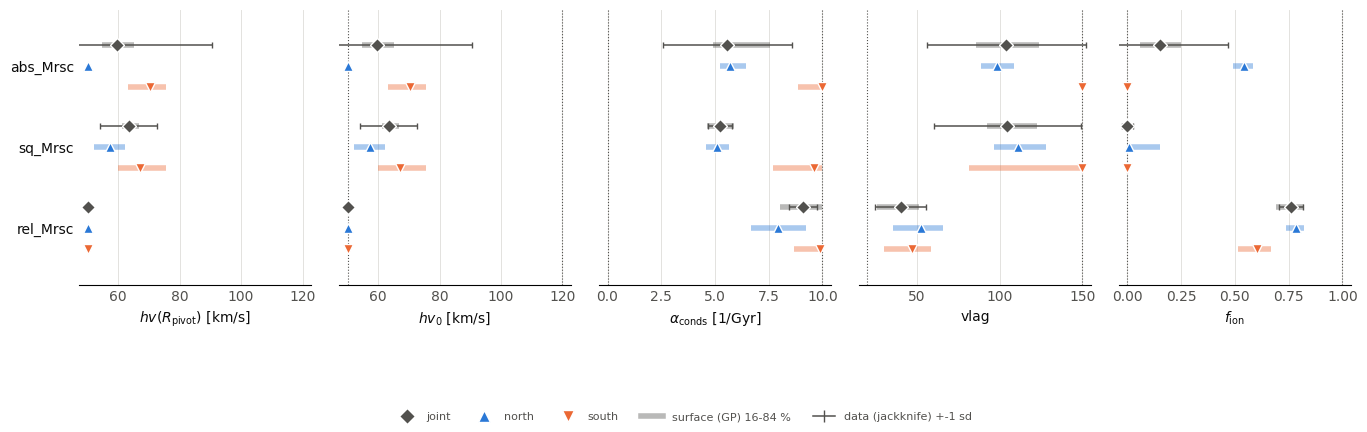

In [21]:
RUN_HEMI = True
if RUN_HEMI:
    HEMI = {"north": lambda B, V, L: B > 0, "south": lambda B, V, L: B < 0}
    GRP = {}

    for hemi, sel in HEMI.items():
        R_h = gr.evaluate_pack(pack, cmp, names=list(RUNS_FIT), 
                               cache=RES_DIR / f"grid_resid_{hemi}_{TAG}.pkl", 
                               workers=WORKERS, fn=gr.subset_evaluator(sel))
        GRP[hemi] = gr.optima_cached(RES_DIR / f"grid_fit_{hemi}_{TAG}.pkl", 
                                     R_h, RUNS_FIT, CHECK_KEYS, NOISE, box, feat, n_draws=200, 
                                     n_restarts=4, jackknife=False, bias=BIAS)
    GRP["joint"] = OUT_C

    print()
    gr.print_comparison({"north": GRP["north"], "south": GRP["south"], "joint": GRP["joint"]}, box, keys=CHECK_KEYS)
    fig = gr.plot_optima_groups({"joint": GRP["joint"], "north": GRP["north"], "south": GRP["south"]}, 
                                box, keys=CHECK_KEYS, feat=feat)
    plt.show()

**Reading it.** 

The last column of the table is the difference of the north and south optimum in units of their combined surface spread (if the spread is zero there, the agreement is the answer). 

In the plot, one row per residual, grey is the both hemispheres together, blue is the north, orange is the south. Two hemispheres on the same edge say that the pull towards that edge does not come from one half of the sky. Two different places say that the joint fit averages two different answers.